In [1]:
!pip install roboflow torch torchvision torchmetrics albumentations -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 144.8 MB/s eta 0:00:00


In [2]:
import os
import glob
import zipfile
import shutil
import random
import time
from collections import defaultdict
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import torch
import torch.utils.data
from torch.cuda.amp import GradScaler, autocast
import torchvision
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    fasterrcnn_mobilenet_v3_large_fpn
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    FasterRCNN_MobileNet_V3_Large_FPN_Weights
)
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)
import seaborn as sns
from roboflow import Roboflow
from IPython.display import display, HTML
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [3]:
# === KONFIGURASI ===
# Ganti dengan API key dan workspace/project Anda
API_KEY = os.getenv("ROBOFLOW_API_KEY", "qkrwwn0zGtWk0FFezlwt")
WORKSPACE_NAME = "datasetbariq"
PROJECT_NAME = "violations-in-lab"
VERSION_NUMBER = 1
MODEL_FORMAT = "voc"

# Device
DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

# Training
BATCH_SIZE = 8
NUM_EPOCHS = 60
# LEARNING_RATE = 0.005
LEARNING_RATE = 0.0001
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
STEP_SIZE = 5
MILESTONES = [15, 25]
GAMMA = 0.1

print(f"Device: {DEVICE}")

Device: cuda


In [4]:
# ==========================================
# CELL 4: DOWNLOAD MANUAL (HARD FIX)
# ==========================================

# 1. KONFIGURASI LINK
# Paste link dari Tab "Terminal" di Roboflow di sini!
# Contoh format: "https://universe.roboflow.com/ds/xyz...?key=123..."
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/rlCOT4pUUB?key=nUG1xVZEJU" #8020 TANPA PREPROCESSING
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/kV7YQNOe8n?key=IiHDmCrETX" #8020
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/uxbqBCp6sJ?key=UtzrJD8qio" #7030
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/gLz2jeTxRE?key=yQGxelvVLu" #701515
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/3WMToKYpSt?key=dU8plpaHEo" #702010 Augmentation Beda
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/zg7g7jAQAH?key=GjQHfhUtXn" #702010 Tanpa Preprocessing dan Augmentation
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/OsZs5g2Tam?key=AB6Z9peNm7" #702010 Preprocessing AO, RS640
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/UJigMQzLqK?key=gvnPXT41dN" #702010 Preprocessing AO, RS640, AAC Histo
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/skULf30k8d?key=7f5IzBbY9x" #702010 Preprocessing AO, RS640, AAC Histo, Gray
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/szb7Xi7GYj?key=j2VHyVmXqc" #702010 Augmentation Flip, 90r
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/O9vWKp8mEu?key=okzjFVYXfA" #702010 Augmentation Flip, Bright
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/TJrgXBbjHl?key=u1U5eEzZbN" #702010 Augmentation Flip, Shear
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/hwlP8YNwFA?key=lB8LhUQkSY" #702010 Gabungan #1
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/IH53GGhCMp?key=JvFP93WS9G" #702010 Gabungan #2
# New
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/TfK5vmdJYU?key=bdCZ71bspV" #702010 Tanpa Preprocessing dan Augmentation
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/zGFKlQvFUc?key=cJ7v5Cjviq" #702010 Preprocessing AO, RS640
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/zAkjNPZu1x?key=70aVbmGqp1" #702010 Preprocessing AO, RS640, AAC Histo
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/J8bjVYRqH5?key=QjwoCnYHIl" #702010 Preprocessing AO, RS640, AAC Histo, Gray
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/jcO6dXaoFV?key=dlBjpTLm8C" #702010 Preprocessing AO, RFB640
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/McQtJBM8XE?key=OysHUfptlB" #702010 Preprocessing AO, RFB640, AAC Histo
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/3O8DwyVcO0?key=G3ufNcagOj" #702010 Preprocessing AO, RFB640, AAC Histo, Gray
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/64d6Ccjj2z?key=PsafOt9b9y" #702010 Augmentation Flip, 90r
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/O3tF61FgIk?key=2NiOkAGiMU" #702010 Augmentation Flip, Bright
# DOWNLOAD_LINK = "https://app.roboflow.com/ds/pADH4hThi7?key=EQu4BETTF0" #702010 Augmentation Flip, Shear

# DOWNLOAD_LINK = "https://app.roboflow.com/ds/u6MMAK79i2?key=dFc6xGtBjZ" #702010 Gabungan #2
DOWNLOAD_LINK = "https://app.roboflow.com/ds/ou2kQlpAqp?key=Pgr8fYkj7s" #702010 Gabungan #2 RFW

# Folder tujuan yang bersih
DATASET_FOLDER = "/content/dataset_manual"

# 2. BERSIH-BERSIH (Hapus data lama yang rusak)
if os.path.exists(DATASET_FOLDER):
    shutil.rmtree(DATASET_FOLDER)
os.makedirs(DATASET_FOLDER, exist_ok=True)

# 3. DOWNLOAD PAKSA (Menggunakan curl system)
print("⏳ Sedang mendownload dataset...")
zip_path = os.path.join(DATASET_FOLDER, "roboflow.zip")
# -L untuk follow redirect, -o untuk output file
os.system(f'curl -L "{DOWNLOAD_LINK}" -o {zip_path}')

# 4. CEK & EKSTRAK
if os.path.exists(zip_path):
    size = os.path.getsize(zip_path)
    print(f"📦 Ukuran file terdownload: {size/1024:.3f} KB")

    if size < 1000: # Jika kurang dari 1KB, pasti error text
        print("❌ ERROR: File terlalu kecil. Link salah atau API Key bermasalah.")
        with open(zip_path, 'r') as f:
            print("Isi file:", f.read())
    else:
        try:
            print("📂 Sedang mengekstrak...")
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(DATASET_FOLDER)
            print("✅ Ekstraksi SUKSES!")

            # Hapus zip biar hemat storage
            os.remove(zip_path)

            # Set variabel global agar Cell 8 bisa baca
            class DatasetDummy:
                location = DATASET_FOLDER
            dataset = DatasetDummy()

        except zipfile.BadZipFile:
            print("❌ ERROR: File masih corrupt. Coba generate version baru di Roboflow.")
else:
    print("❌ Gagal download. File tidak ditemukan.")

⏳ Sedang mendownload dataset...
📦 Ukuran file terdownload: 21769.541 KB
📂 Sedang mengekstrak...
✅ Ekstraksi SUKSES!


In [5]:
# ==========================================
# CELL 5 (FIXED): DATASET CLASS dengan NORMALISASI
# ==========================================

class LabViolationDataset(torch.utils.data.Dataset):
    def __init__(self, root, transforms=None):
        self.root = root
        self.transforms = transforms

        all_files = list(sorted(os.listdir(root)))
        self.imgs = [f for f in all_files if f.lower().endswith(('.jpg', '.jpeg'))]
        self.annotations = [f for f in all_files if f.endswith('.xml')]

        # Definisi Kelas
        self.class_map = {
            'background': 0,
            'playing game phone': 1,
            'sleep': 2,
            'eating': 3
        }

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, self.imgs[idx])
        img_filename = self.imgs[idx]
        xml_filename = os.path.splitext(img_filename)[0] + '.xml'
        annot_path = os.path.join(self.root, xml_filename)

        try:
            img = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Error opening image: {img_path}, skipping...")
            return self.__getitem__((idx + 1) % len(self.imgs))

        try:
            tree = ET.parse(annot_path)
        except ET.ParseError:
            print(f"XML parse error: {annot_path}, skipping...")
            return self.__getitem__((idx + 1) % len(self.imgs))

        root = tree.getroot()

        boxes = []
        labels = []

        for member in root.findall('object'):
            label_text = member.find('name').text.strip().lower()

            # Normalisasi label
            if label_text not in self.class_map:
                if label_text.replace("-", " ") in self.class_map:
                    label_text = label_text.replace("-", " ")
                elif label_text.replace("_", " ") in self.class_map:
                    label_text = label_text.replace("_", " ")
                else:
                    continue

            labels.append(self.class_map[label_text])

            bndbox = member.find('bndbox')
            xmin = int(bndbox.find('xmin').text)
            ymin = int(bndbox.find('ymin').text)
            xmax = int(bndbox.find('xmax').text)
            ymax = int(bndbox.find('ymax').text)
            boxes.append([xmin, ymin, xmax, ymax])

        if len(boxes) == 0:
            return self.__getitem__((idx + 1) % len(self.imgs))

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64)
        image_id = torch.tensor([idx])
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])
        iscrowd = torch.zeros((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd
        }

        if self.transforms is not None:
            img_np = np.array(img)
            augmented = self.transforms(
                image=img_np,
                bboxes=boxes.numpy(),
                labels=labels.numpy()
            )
            # FIX: Convert uint8 to float32 and normalize to [0, 1]
            img = augmented['image'].to(torch.float32) / 255.0
            boxes = torch.as_tensor(augmented['bboxes'], dtype=torch.float32)
            labels = torch.as_tensor(augmented['labels'], dtype=torch.int64)
        else:
            img = torchvision.transforms.ToTensor()(img)

        return img, target

    def __len__(self):
        return len(self.imgs)

In [6]:
# ==========================================
# CELL 6: MODEL DEFINITION + TRANSFORMS (FIXED)
# ==========================================

def get_train_transform():
    return A.Compose([
        A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.6),
        A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
        A.Blur(blur_limit=3, p=0.2),
        A.RandomGamma(gamma_limit=(90, 110), p=0.3),
        ToTensorV2()
    ], bbox_params=A.BboxParams(
        format='pascal_voc',
        label_fields=['labels'],
        min_visibility=0.3,
        clip=True # FIX: Memotong bbox agar tidak melewati batas gambar
    ))

# def get_train_transform():
#     return A.Compose([
#         A.RandomBrightnessContrast(
#             brightness_limit=0.2,
#             contrast_limit=0.2,
#             p=0.6
#         ),
#         # GANTI: hapus var_limit, pakai std_range (albumentations ≥ 2.0)
#         A.GaussNoise(
#             std_range=(0.05, 0.15),   # ← ganti ini
#             p=0.3
#         ),
#         A.Blur(
#             blur_limit=3,
#             p=0.2
#         ),
#         A.RandomGamma(
#             gamma_limit=(90, 110),
#             p=0.3
#         ),
#         ToTensorV2()
#     ], bbox_params=A.BboxParams(
#         format='pascal_voc',
#         label_fields=['labels'],
#         min_visibility=0.3
#     ))

def get_val_transform():
    return A.Compose([
        ToTensorV2()
    ], bbox_params=A.BboxParams(
        format='pascal_voc',
        label_fields=['labels'],
        clip=True # FIX: Memotong bbox agar tidak melewati batas gambar
    ))

def get_model(num_classes, backbone="resnet50", freeze_backbone=True):
    print(f"🔄 Loading Faster R-CNN backbone: {backbone}")
    if backbone == "resnet50":
        weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
        model = fasterrcnn_resnet50_fpn_v2(weights=weights)
        if freeze_backbone:
            for param in model.backbone.body.layer1.parameters(): param.requires_grad = False
            for param in model.backbone.body.layer2.parameters(): param.requires_grad = False
    elif backbone == "mobilenet":
        weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
        model = fasterrcnn_mobilenet_v3_large_fpn(weights=weights)
        if freeze_backbone:
            for param in model.backbone.parameters(): param.requires_grad = False
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

def collate_fn(batch):
    return tuple(zip(*batch))

In [7]:
# ==========================================
# CELL 7: EVALUATION LOGIC (FIXED RETURN KEYS)
# ==========================================

def box_iou_calc(box1, box2):
    # box1: (N, 4), box2: (M, 4)
    # Return: (N, M)
    area1 = (box1[:, 2] - box1[:, 0]) * (box1[:, 3] - box1[:, 1])
    area2 = (box2[:, 2] - box2[:, 0]) * (box2[:, 3] - box2[:, 1])

    lt = torch.max(box1[:, None, :2], box2[:, :2])
    rb = torch.min(box1[:, None, 2:], box2[:, 2:])

    wh = (rb - lt).clamp(min=0)
    inter = wh[:, :, 0] * wh[:, :, 1]
    union = area1[:, None] + area2 - inter

    return inter / union

def calculate_classic_metrics(model, data_loader, device, conf_threshold=0.7, iou_threshold=0.7):
    model.eval()

    tp = 0
    fp = 0
    fn = 0
    total_gt = 0

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            outputs = model(images)

            for i, output in enumerate(outputs):
                pred_boxes = output['boxes']
                pred_scores = output['scores']
                pred_labels = output['labels']

                gt_boxes = targets[i]['boxes'].to(device)
                gt_labels = targets[i]['labels'].to(device)

                # 1. Filter by Confidence Threshold
                mask = pred_scores >= conf_threshold
                pred_boxes = pred_boxes[mask]
                pred_labels = pred_labels[mask]

                total_gt += len(gt_boxes)

                if len(pred_boxes) == 0:
                    fn += len(gt_boxes)
                    continue

                if len(gt_boxes) == 0:
                    fp += len(pred_boxes)
                    continue

                # 2. Matching Strategy (Greedy)
                # Hitung IoU matrix antara semua prediksi vs semua ground truth
                iou_matrix = box_iou_calc(pred_boxes, gt_boxes)

                matched_gt = set()

                # Iterasi setiap prediksi
                for p_idx in range(len(pred_boxes)):
                    # Cari GT dengan IoU terbesar untuk prediksi ini
                    best_iou, best_gt_idx = iou_matrix[p_idx].max(dim=0)

                    # Syarat TP:
                    # a. IoU > Threshold (misal 0.7)
                    # b. Label kelas sama
                    # c. GT tersebut belum terpakai (matched) oleh prediksi lain
                    if (best_iou >= iou_threshold) and \
                       (pred_labels[p_idx] == gt_labels[best_gt_idx]) and \
                       (best_gt_idx.item() not in matched_gt):

                        tp += 1
                        matched_gt.add(best_gt_idx.item())
                    else:
                        fp += 1

                # Sisa GT yang tidak termatch adalah False Negative
                # (Dihitung di akhir: FN = Total GT - TP)

    fn = total_gt - tp

    # Hitung Metrik
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1_score = 2 * (precision * recall) / (precision + recall + 1e-6)

    return precision, recall, f1_score

def evaluate_model_detailed(model, data_loader, device, class_map):
    # --- 1. HITUNG VALIDATION LOSS ---
    model.train()
    val_loss_accum = 0
    total_images = 0

    # Hitung jumlah gambar per kelas
    class_image_counts = {k: 0 for k in class_map.values() if k != 0}

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            val_loss_accum += losses.item()

            total_images += len(images)
            for t in targets:
                unique_labels = torch.unique(t['labels']).cpu().tolist()
                for label in unique_labels:
                    if label in class_image_counts:
                        class_image_counts[label] += 1

    avg_val_loss = val_loss_accum / len(data_loader)

    # --- 2. HITUNG METRIK DETEKSI ---
    model.eval()
    print("⏳ Menghitung metrik evaluasi...")

    metric = MeanAveragePrecision(iou_type="bbox", class_metrics=True)
    inference_times = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            start = time.time()
            outputs = model(images)
            end = time.time()
            inference_times.append((end - start) / len(images))

            metric.update(outputs, targets)

    # --- 3. KOMPILASI HASIL ---
    results = metric.compute()

    # Ambil Metrik Global
    map50_all = results['map_50'].item()
    map_all = results['map'].item()        # Ini adalah mAP 0.5:0.95
    recall_all = results['mar_100'].item()

    # Data Per Kelas
    map_per_class = results['map_per_class']
    recall_per_class = results['mar_100_per_class']

    # --- MEMBUAT TABEL FORMAT YOLO ---
    print("\n" + "="*85)
    print(f"{'Class':<20} {'Images':<10} {'Recall':<12} {'mAP50':<12} {'mAP50-95':<12}")
    print("-" * 85)

    # Baris 'all'
    print(f"{'all':<20} {total_images:<10} {recall_all:.3f}       {map50_all:.3f}       {map_all:.3f}")

    ap_data = []
    rev_class_map = {v: k for k, v in class_map.items() if v != 0}
    sorted_ids = sorted(rev_class_map.keys())

    for i, class_id in enumerate(sorted_ids):
        name = rev_class_map[class_id]
        num_imgs = class_image_counts.get(class_id, 0)

        if i < len(recall_per_class):
            r_cls = recall_per_class[i].item()
            map_cls = map_per_class[i].item() # mAP 0.5:0.95 per kelas
        else:
            r_cls = 0.0
            map_cls = 0.0

        print(f"{name:<20} {num_imgs:<10} {r_cls:.3f}       {'-':<12} {map_cls:.3f}")
        ap_data.append([name, r_cls, map_cls])

    print("="*85 + "\n")

    df_ap = pd.DataFrame(ap_data, columns=['Class', 'Recall', 'mAP50-95'])
    avg_inf_time = np.mean(inference_times)
    fps = 1.0 / avg_inf_time if avg_inf_time > 0 else 0

    # RETURN DICTIONARY LENGKAP (Pastikan kuncinya ada semua)
    return {
        'mAP@0.5': map50_all,
        'map_50_95': map_all,
        'recall': recall_all,
        'val_loss': avg_val_loss,
        'fps': fps,
        'inference_time_ms': avg_inf_time * 1000,
        'ap_per_class': df_ap
    }

def calculate_per_class_metrics(model, data_loader, device, class_map,
                                 conf_threshold=0.7, iou_threshold=0.7):
    """
    Menghitung TP, FN, dan Recall PER KELAS.

    Tujuan: Menjawab "kelas mana yang paling sulit dideteksi?"

    Args:
        model          : Model yang akan dievaluasi
        data_loader    : DataLoader test
        device         : cuda / cpu
        class_map      : Dict nama_kelas -> id (e.g. {'sleep': 2, ...})
        conf_threshold : Ambang batas confidence (default 0.5)
        iou_threshold  : Ambang batas IoU untuk TP (default 0.5)

    Returns:
        DataFrame dengan kolom:
        [Jenis Pelanggaran, Jumlah Data Test (BB), Terdeteksi Benar (TP),
         Gagal Terdeteksi (FN), Akurasi/Recall (%)]
    """
    model.eval()

    # Siapkan counter per kelas (skip background = id 0)
    rev_class_map = {v: k for k, v in class_map.items() if v != 0}
    class_ids     = sorted(rev_class_map.keys())

    total_gt = {cid: 0 for cid in class_ids}
    total_tp  = {cid: 0 for cid in class_ids}

    with torch.no_grad():
        for images, targets in data_loader:
            images = list(img.to(device) for img in images)
            outputs = model(images)

            for i, output in enumerate(outputs):
                pred_boxes  = output['boxes']
                pred_scores = output['scores']
                pred_labels = output['labels']

                gt_boxes  = targets[i]['boxes'].to(device)
                gt_labels = targets[i]['labels'].to(device)

                # --- Hitung total GT per kelas ---
                for cid in class_ids:
                    mask_gt = (gt_labels == cid)
                    total_gt[cid] += mask_gt.sum().item()

                # --- Filter prediksi berdasar confidence ---
                conf_mask   = pred_scores >= conf_threshold
                pred_boxes  = pred_boxes[conf_mask]
                pred_labels = pred_labels[conf_mask]

                if len(pred_boxes) == 0 or len(gt_boxes) == 0:
                    continue  # TP tetap 0 untuk batch ini

                # --- Matching Greedy per pasangan (pred, gt) ---
                # Hitung IoU matrix
                area1 = (pred_boxes[:, 2] - pred_boxes[:, 0]) * \
                        (pred_boxes[:, 3] - pred_boxes[:, 1])
                area2 = (gt_boxes[:, 2] - gt_boxes[:, 0]) * \
                        (gt_boxes[:, 3] - gt_boxes[:, 1])

                lt = torch.max(pred_boxes[:, None, :2], gt_boxes[:, :2])
                rb = torch.min(pred_boxes[:, None, 2:], gt_boxes[:, 2:])
                wh = (rb - lt).clamp(min=0)
                inter = wh[:, :, 0] * wh[:, :, 1]
                union = area1[:, None] + area2 - inter
                iou_matrix = inter / (union + 1e-6)

                matched_gt = set()
                for p_idx in range(len(pred_boxes)):
                    best_iou, best_gt_idx = iou_matrix[p_idx].max(dim=0)
                    best_gt_idx = best_gt_idx.item()

                    if (best_iou >= iou_threshold and
                            pred_labels[p_idx] == gt_labels[best_gt_idx] and
                            best_gt_idx not in matched_gt):
                        cid = pred_labels[p_idx].item()
                        if cid in total_tp:
                            total_tp[cid] += 1
                        matched_gt.add(best_gt_idx)

    # --- Susun tabel ---
    # Label nama yang lebih ramah untuk laporan skripsi
    display_names = {
        'playing game phone': 'Game (Main HP)',
        'sleep':              'Tidur',
        'eating':             'Makan',
    }

    rows = []
    for cid in class_ids:
        name     = rev_class_map[cid]
        gt_count = total_gt[cid]
        tp       = total_tp[cid]
        fn       = gt_count - tp
        recall   = (tp / gt_count * 100) if gt_count > 0 else 0.0

        rows.append({
            'Jenis Pelanggaran':           display_names.get(name, name),
            'Jumlah Data Test (BB)':       gt_count,
            'Terdeteksi Benar (TP)':       tp,
            'Gagal Terdeteksi (FN)':       fn,
            'Akurasi / Recall (%)':        f"{recall:.1f}%",
        })

    df_result = pd.DataFrame(rows)
    return df_result

In [8]:
# ==========================================
# CELL 8: DATASET LOADING (FIXED NORMALIZATION)
# ==========================================

if 'dataset' not in globals():
    class DatasetDummy: location = "/content/dataset_manual"
    dataset = DatasetDummy()

train_dir = os.path.join(dataset.location, "train")
valid_dir = os.path.join(dataset.location, "valid")
use_predefined_split = os.path.exists(train_dir) and os.path.exists(valid_dir)

if use_predefined_split:
    dataset_train = LabViolationDataset(train_dir, transforms=get_train_transform())
    dataset_valid = LabViolationDataset(valid_dir, transforms=get_val_transform())
else:
    # Logic split manual tetap ada tapi dipastikan normalisasinya benar
    class SubsetWithTransform(torch.utils.data.Subset):
        def __init__(self, dataset, indices, transforms=None):
            super().__init__(dataset, indices)
            self.transforms = transforms
        def __getitem__(self, idx):
            img, target = super().__getitem__(idx)
            # Jika ada transform, terapkan dan pastikan normalisasi float32 / 255
            if self.transforms is not None:
                img_np = np.array(Image.open(os.path.join(self.dataset.root, self.dataset.imgs[self.indices[idx]])).convert("RGB"))
                augmented = self.transforms(image=img_np, bboxes=target['boxes'].numpy(), labels=target['labels'].numpy())
                img = augmented['image'].to(torch.float32) / 255.0
                target['boxes'] = torch.as_tensor(augmented['bboxes'], dtype=torch.float32)
                target['labels'] = torch.as_tensor(augmented['labels'], dtype=torch.int64)
            return img, target

    target_dir = dataset.location # fallback
    full_dataset = LabViolationDataset(target_dir, transforms=None)
    indices = torch.randperm(len(full_dataset)).tolist()
    split = int(len(full_dataset) * 0.8)
    dataset_train = SubsetWithTransform(full_dataset, indices[:split], transforms=get_train_transform())
    dataset_valid = SubsetWithTransform(full_dataset, indices[split:], transforms=get_val_transform())

train_loader = torch.utils.data.DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=2)
valid_loader = torch.utils.data.DataLoader(dataset_valid, batch_size=1, shuffle=False, collate_fn=collate_fn, num_workers=2)
print("✅ DataLoader Siap dengan Fix BBox Clip & Normalization!")

✅ DataLoader Siap dengan Fix BBox Clip & Normalization!


Argument(s) 'var_limit' are not valid for transform GaussNoise
Got processor for bboxes, but no transform to process it.


In [9]:
num_classes = 4
model = get_model(num_classes, backbone="resnet50", freeze_backbone=True)
model.to(DEVICE)

# Optimizer: AdamW (lebih stabil dari SGD untuk data kecil)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning Rate Scheduler: ReduceLROnPlateau (adaptive)
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=5,
    cooldown=2
)

scaler = torch.amp.GradScaler('cuda')

history = {
    'train_loss': [], 'val_loss': [], 'map_50': [],
    'loss_classifier': [], 'loss_box_reg': [],
    'loss_objectness': [], 'loss_rpn_box_reg': []
}

if hasattr(dataset_train, 'class_map'):
    class_map_ref = dataset_train.class_map
else:
    class_map_ref = dataset_train.dataset.class_map

# BARU: Early stopping configuration
PATIENCE = 10
epochs_no_improve = 0
best_map = 0.0
best_epoch = 0
best_epoch_details = {}

print("🚀 Mulai Training dengan Early Stopping...")
print(f"⏸ Patience: {PATIENCE} epoch")
start_time = time.time()

for epoch in range(NUM_EPOCHS):
    model.train()
    epoch_losses = {'total': 0, 'cls': 0, 'box': 0, 'obj': 0, 'rpn_box': 0}

    # Training
    for images, targets in train_loader:
        images = list(image.to(DEVICE) for image in images)
        targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        epoch_losses['total'] += losses.item()
        epoch_losses['cls'] += loss_dict['loss_classifier'].item()
        epoch_losses['box'] += loss_dict['loss_box_reg'].item()
        epoch_losses['obj'] += loss_dict['loss_objectness'].item()
        epoch_losses['rpn_box'] += loss_dict['loss_rpn_box_reg'].item()

        scaler.scale(losses).backward()
        scaler.step(optimizer)
        scaler.update()

    len_data = len(train_loader)

    history['train_loss'].append(epoch_losses['total'] / len_data)
    history['loss_classifier'].append(epoch_losses['cls'] / len_data)
    history['loss_box_reg'].append(epoch_losses['box'] / len_data)
    history['loss_objectness'].append(epoch_losses['obj'] / len_data)
    history['loss_rpn_box_reg'].append(epoch_losses['rpn_box'] / len_data)

    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {history['train_loss'][-1]:.3f}")

    # Evaluation
    eval_results = evaluate_model_detailed(model, valid_loader, DEVICE, class_map_ref)

    history['map_50'].append(eval_results['mAP@0.5'])
    history['val_loss'].append(eval_results['val_loss'])

    print(f"   >>> Val Loss: {eval_results['val_loss']:.3f} | mAP@0.5: {eval_results['mAP@0.5']:.3f}")

    # Best model checkpoint
    if eval_results['mAP@0.5'] > best_map:
        best_map = eval_results['mAP@0.5']
        best_epoch = epoch + 1
        epochs_no_improve = 0
        best_epoch_details = eval_results.copy()
        torch.save(model.state_dict(), "best_model.pth")
        print(f"   💾 Model Terbaik! (mAP: {best_map:.3f})")
    else:
        epochs_no_improve += 1
        print(f"   ⏳ No improvement ({epochs_no_improve}/{PATIENCE})")

    # Adjust learning rate
    lr_scheduler.step(eval_results['mAP@0.5'])

    # Early stopping
    if epochs_no_improve >= PATIENCE:
        print(f"\n🛑 Early stopping di epoch {epoch+1}")
        print(f"   Best: Epoch {best_epoch} (mAP: {best_map:.3f})")
        break

total_time = (time.time() - start_time) / 60
print("\n" + "★"*60)
print(f"✅ Training Selesai: {total_time:.2f} menit")
print(f"🏆 Best Epoch: {best_epoch} (mAP: {best_map:.3f})")
print("★"*60)

if best_epoch_details:
    print(f"\n📊 HASIL TERBAIK (Epoch {best_epoch}):")
    print(f"• mAP@0.5        : {best_epoch_details.get('mAP@0.5', 0):.3f}")
    print(f"• mAP@0.5-0.95   : {best_epoch_details.get('map_50_95', 0):.3f}")
    print(f"• Recall         : {best_epoch_details.get('recall', 0):.3f}")
    print(f"• Val Loss       : {best_epoch_details.get('val_loss', 0):.3f}")
    print("-" * 40)
    if 'ap_per_class' in best_epoch_details:
        print("Per Kelas:")
        print(best_epoch_details['ap_per_class'].to_string(index=False))
    print("="*60)

torch.save(model.state_dict(), "final_model.pth")

🔄 Loading Faster R-CNN backbone: resnet50
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 99.3MB/s]


🚀 Mulai Training dengan Early Stopping...
⏸ Patience: 10 epoch

Epoch 1/60 | Train Loss: 0.416
⏳ Menghitung metrik evaluasi...

Class                Images     Recall       mAP50        mAP50-95    
-------------------------------------------------------------------------------------
all                  48         0.405       0.579       0.244
playing game phone   18         0.503       -            0.376
sleep                26         0.403       -            0.231
eating               11         0.309       -            0.123

   >>> Val Loss: 0.269 | mAP@0.5: 0.579
   💾 Model Terbaik! (mAP: 0.579)

Epoch 2/60 | Train Loss: 0.298
⏳ Menghitung metrik evaluasi...

Class                Images     Recall       mAP50        mAP50-95    
-------------------------------------------------------------------------------------
all                  48         0.514       0.857       0.401
playing game phone   18         0.550       -            0.402
sleep                26         0.421      

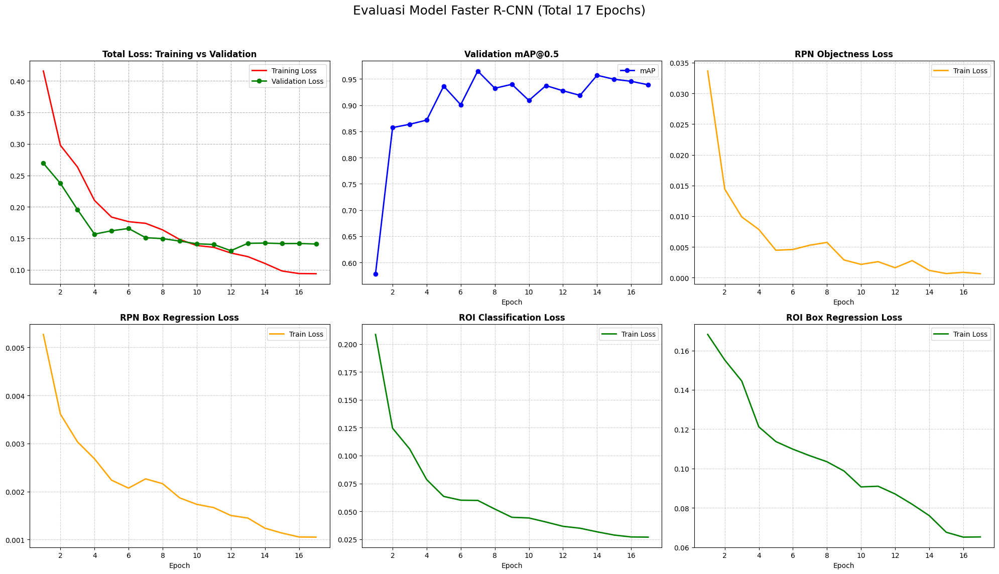

In [10]:
# ==========================================
# CELL 10: VISUALISASI GRAFIK (LAYOUT 2x3)
# ==========================================

def plot_complete_metrics(history):
    if 'train_loss' not in history or len(history['train_loss']) == 0:
        print("❌ Data history kosong.")
        return

    num_epochs = len(history['train_loss'])
    epochs = range(1, num_epochs + 1)

    val_len = len(history.get('val_loss', []))
    val_epochs = np.linspace(num_epochs/val_len, num_epochs, num=val_len) if val_len > 0 else []

    # --- SETUP LAYOUT 2 BARIS x 3 KOLOM ---
    fig, axs = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle(f'Evaluasi Model Faster R-CNN (Total {num_epochs} Epochs)', fontsize=18, y=0.98)

    # Helper function
    def plot_line(ax, x, y, title, color, label, marker=None):
        if len(y) > 0:
            ax.plot(x, y, color=color, label=label, marker=marker, linewidth=2)
            ax.set_title(title, fontweight='bold')
            ax.set_xlabel('Epoch')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend()

    # --- BARIS 1 ---
    # 1. Total Loss (Train vs Valid)
    ax = axs[0, 0]
    ax.plot(epochs, history['train_loss'], 'r-', label='Training Loss', linewidth=2)
    if len(val_epochs) > 0:
        ax.plot(val_epochs, history['val_loss'], 'g-o', label='Validation Loss', linewidth=2)
    ax.set_title('Total Loss: Training vs Validation', fontweight='bold')
    ax.grid(True, linestyle='--')
    ax.legend()

    # 2. Validation mAP
    plot_line(axs[0, 1], val_epochs, history.get('map_50', []), 'Validation mAP@0.5', 'blue', 'mAP', 'o')

    # 3. RPN Objectness
    plot_line(axs[0, 2], epochs, history.get('loss_objectness', []), 'RPN Objectness Loss', 'orange', 'Train Loss')

    # --- BARIS 2 ---
    # 4. RPN Box Reg
    plot_line(axs[1, 0], epochs, history.get('loss_rpn_box_reg', []), 'RPN Box Regression Loss', 'orange', 'Train Loss')

    # 5. ROI Classification
    plot_line(axs[1, 1], epochs, history.get('loss_classifier', []), 'ROI Classification Loss', 'green', 'Train Loss')

    # 6. ROI Box Reg
    plot_line(axs[1, 2], epochs, history.get('loss_box_reg', []), 'ROI Box Regression Loss', 'green', 'Train Loss')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

plot_complete_metrics(history)

In [11]:
# ==========================================
# CELL 11: LOAD TEST DATASET (FIXED FUNCTION NAME)
# ==========================================

# 1. Cek Lokasi Folder Test
TEST_DIR = os.path.join(dataset.location, "test")

if not os.path.exists(TEST_DIR):
    print(f"⚠️ Folder Test tidak ditemukan di: {TEST_DIR}")
    test_candidates = glob.glob(os.path.join(dataset.location, "*test*"))
    if test_candidates:
        TEST_DIR = test_candidates[0]
        print(f"✅ Ditemukan folder alternatif: {TEST_DIR}")
    else:
        raise ValueError("❌ Gagal menemukan folder data test!")
else:
    print(f"📂 Folder Test ditemukan: {TEST_DIR}")

# 2. Setup Dataset & DataLoader Test
try:
    # FIX: Menggunakan get_val_transform() karena get_transform() tidak ada
    dataset_test = LabViolationDataset(TEST_DIR, get_val_transform())

    test_loader = torch.utils.data.DataLoader(
        dataset_test,
        batch_size=1,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=2,
        pin_memory=True
    )

    print(f"📊 Jumlah Data Test: {len(dataset_test)} gambar")
    print("✅ Test DataLoader Siap Digunakan!")

except Exception as e:
    print(f"❌ Error memuat data test: {e}")

📂 Folder Test ditemukan: /content/dataset_manual/test
📊 Jumlah Data Test: 24 gambar
✅ Test DataLoader Siap Digunakan!


Got processor for bboxes, but no transform to process it.


In [12]:
# ============================================================
# GANTI SELURUH ISI CELL 12 dengan kode berikut
# ============================================================

print("🚀 Memulai Evaluasi Akhir pada Data Test...")

if not os.path.exists("best_model.pth"):
    print("⚠️ 'best_model.pth' tidak ditemukan. Menggunakan model saat ini.")
else:
    print("📥 Memuat model terbaik dari 'best_model.pth'...")
    model.load_state_dict(torch.load("best_model.pth"))

model.to(DEVICE)

# --- 1. Evaluasi mAP (Standar Object Detection) ---
test_results_map = evaluate_model_detailed(
    model, test_loader, DEVICE, dataset_test.class_map
)

# --- 2. Evaluasi Precision/Recall Klasik (Global) ---
CONF_THRESH = 0.7
IOU_THRESH  = 0.7

print(f"⏳ Menghitung Precision/Recall Klasik (Conf={CONF_THRESH}, IoU={IOU_THRESH})...")
cls_precision, cls_recall, cls_f1 = calculate_classic_metrics(
    model, test_loader, DEVICE, conf_threshold=CONF_THRESH, iou_threshold=IOU_THRESH
)

# --- 3. Evaluasi Per Kelas (Sesuai Permintaan Dosen) ---
print("⏳ Menghitung metrik per kelas...")
df_per_class = calculate_per_class_metrics(
    model, test_loader, DEVICE, dataset_test.class_map,
    conf_threshold=CONF_THRESH, iou_threshold=IOU_THRESH
)

# --- 4. Tampilkan Laporan ---
print("\n" + "★"*55)
print("HASIL AKHIR PENGUJIAN (TEST SET)")
print("★"*55)
print(f"Dasar Evaluasi: Conf > {CONF_THRESH}  &  IoU > {IOU_THRESH}")
print("-" * 55)
print(f"• mAP@0.5          : {test_results_map['mAP@0.5']:.3f}")
print(f"• Precision (Global): {cls_precision:.3f}")
print(f"• Recall (Global)   : {cls_recall:.3f}")
print(f"• F1-Score          : {cls_f1:.3f}")
print(f"• Speed (FPS)       : {test_results_map['fps']:.2f} fps")
print(f"• Inference Time    : {test_results_map['inference_time_ms']:.1f} ms/img")
print("=" * 55)

# --- 5. Tabel Per Kelas (Permintaan Dosen) ---
print("\n" + "═"*65)
print("  PERFORMA MODEL PER JENIS PELANGGARAN")
print("  (Kelas mana yang paling sulit dideteksi?)")
print("═"*65)
display(df_per_class.to_string(index=False))

# Tampilkan juga sebagai tabel HTML agar lebih rapi di Colab
from IPython.display import display as ipy_display
ipy_display(df_per_class)

# --- 6. Analisis Otomatis ---
print("\n📊 Analisis Otomatis:")
recalls = df_per_class['Akurasi / Recall (%)'].apply(lambda x: float(x.strip('%')))
if recalls.nunique() == 1:
    print(f"  Semua kelas mencapai Recall {recalls.iloc[0]:.1f}% — tidak ada kelas yang sulit dideteksi!")
else:
    min_row = df_per_class.loc[recalls.idxmin()]
    max_row = df_per_class.loc[recalls.idxmax()]
    print(f"  Paling mudah: {max_row['Jenis Pelanggaran']} (Recall {max_row['Akurasi / Recall (%)']})")
    print(f"  Paling sulit: {min_row['Jenis Pelanggaran']} (Recall {min_row['Akurasi / Recall (%)']})")

🚀 Memulai Evaluasi Akhir pada Data Test...
📥 Memuat model terbaik dari 'best_model.pth'...
⏳ Menghitung metrik evaluasi...

Class                Images     Recall       mAP50        mAP50-95    
-------------------------------------------------------------------------------------
all                  24         0.605       0.978       0.520
playing game phone   10         0.633       -            0.506
sleep                13         0.567       -            0.488
eating               6          0.614       -            0.565

⏳ Menghitung Precision/Recall Klasik (Conf=0.7, IoU=0.7)...
⏳ Menghitung metrik per kelas...

★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
HASIL AKHIR PENGUJIAN (TEST SET)
★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★★
Dasar Evaluasi: Conf > 0.7  &  IoU > 0.7
-------------------------------------------------------
• mAP@0.5          : 0.978
• Precision (Global): 0.600
• Recall (Global)   : 0.750
• F1-Score          : 0.667
• Speed (FPS)       

'Jenis Pelanggaran  Jumlah Data Test (BB)  Terdeteksi Benar (TP)  Gagal Terdeteksi (FN) Akurasi / Recall (%)\n   Game (Main HP)                     18                     14                      4                77.8%\n            Tidur                     15                     10                      5                66.7%\n            Makan                      7                      6                      1                85.7%'

,Jenis Pelanggaran,Jumlah Data Test (BB),Terdeteksi Benar (TP),Gagal Terdeteksi (FN),Akurasi / Recall (%)
0,Game (Main HP),18,14,4,77.8%
1,Tidur,15,10,5,66.7%
2,Makan,7,6,1,85.7%



📊 Analisis Otomatis:
  Paling mudah: Makan (Recall 85.7%)
  Paling sulit: Tidur (Recall 66.7%)


📂 Menampilkan 24 gambar dari Data Test (Urut)...


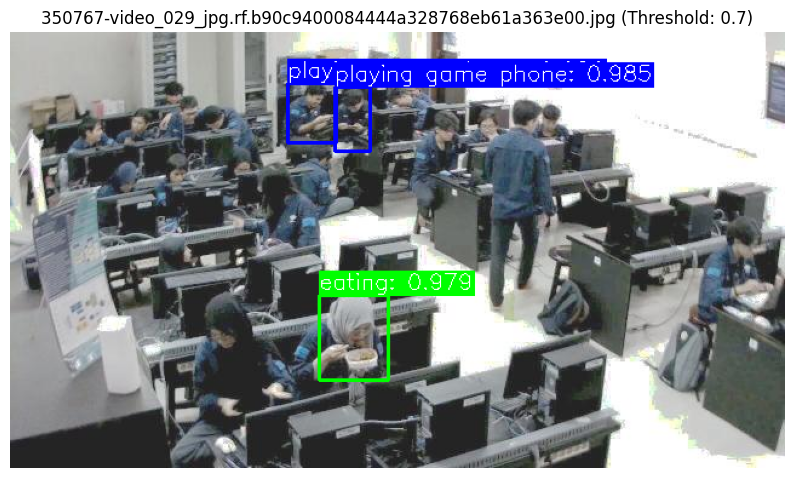

📋 Hasil Deteksi untuk 350767-video_029_jpg.rf.b90c9400084444a328768eb61a363e00.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.986
1,2,playing game phone,0.985
2,3,eating,0.979


--------------------------------------------------------------------------------


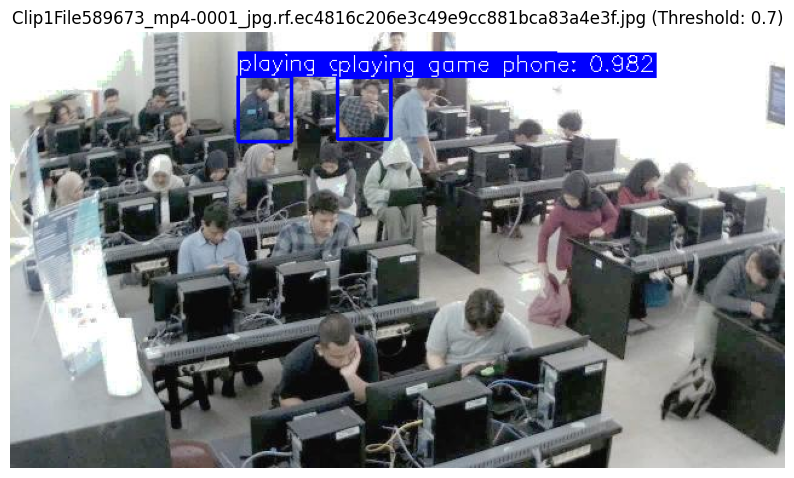

📋 Hasil Deteksi untuk Clip1File589673_mp4-0001_jpg.rf.ec4816c206e3c49e9cc881bca83a4e3f.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.986
1,2,playing game phone,0.982


--------------------------------------------------------------------------------


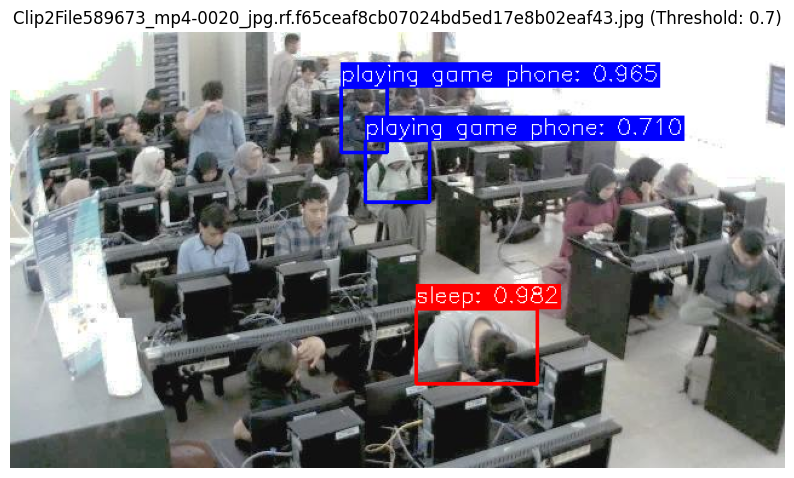

📋 Hasil Deteksi untuk Clip2File589673_mp4-0020_jpg.rf.f65ceaf8cb07024bd5ed17e8b02eaf43.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.982
1,2,playing game phone,0.965
2,3,playing game phone,0.710


--------------------------------------------------------------------------------


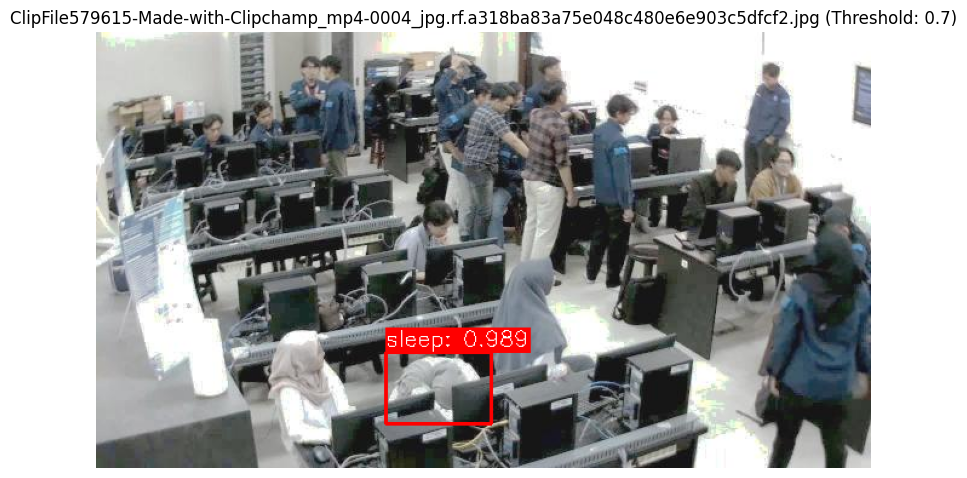

📋 Hasil Deteksi untuk ClipFile579615-Made-with-Clipchamp_mp4-0004_jpg.rf.a318ba83a75e048c480e6e903c5dfcf2.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.989


--------------------------------------------------------------------------------


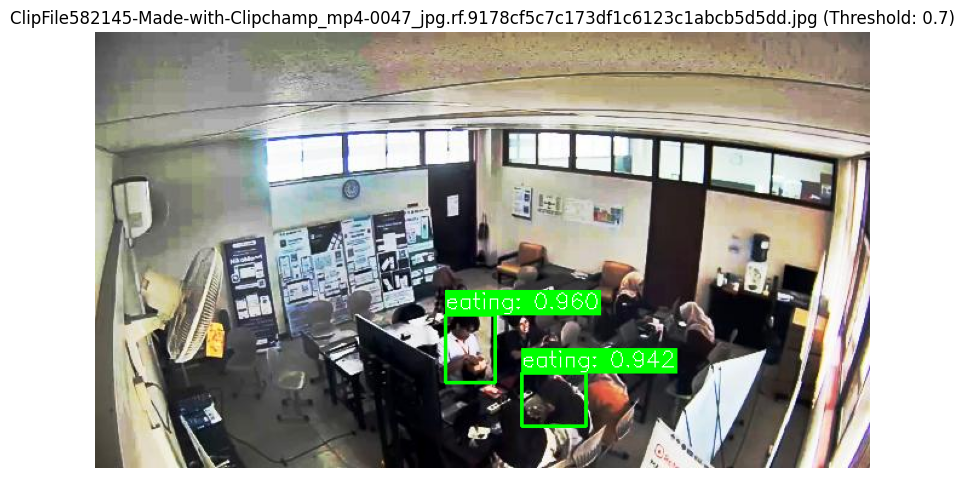

📋 Hasil Deteksi untuk ClipFile582145-Made-with-Clipchamp_mp4-0047_jpg.rf.9178cf5c7c173df1c6123c1abcb5d5dd.jpg:


,No,Pelanggaran,Confidence
0,1,eating,0.960
1,2,eating,0.942


--------------------------------------------------------------------------------


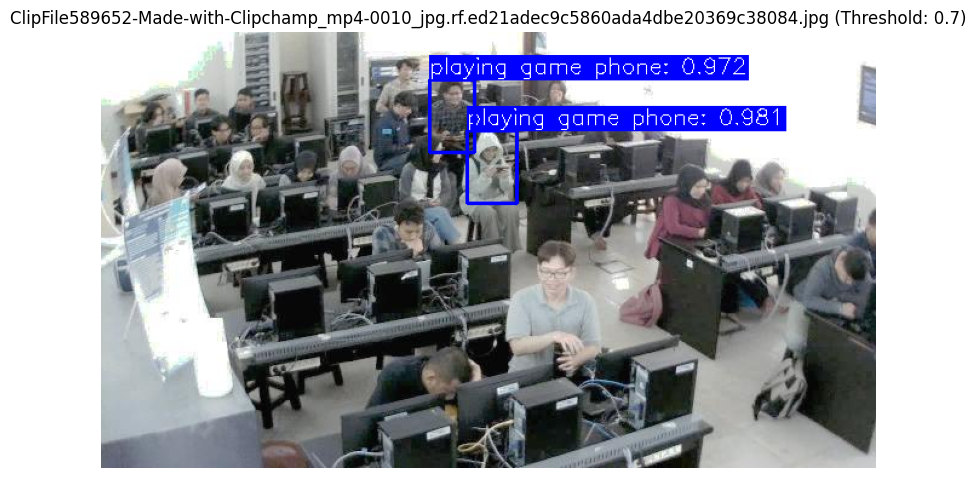

📋 Hasil Deteksi untuk ClipFile589652-Made-with-Clipchamp_mp4-0010_jpg.rf.ed21adec9c5860ada4dbe20369c38084.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.981
1,2,playing game phone,0.972


--------------------------------------------------------------------------------


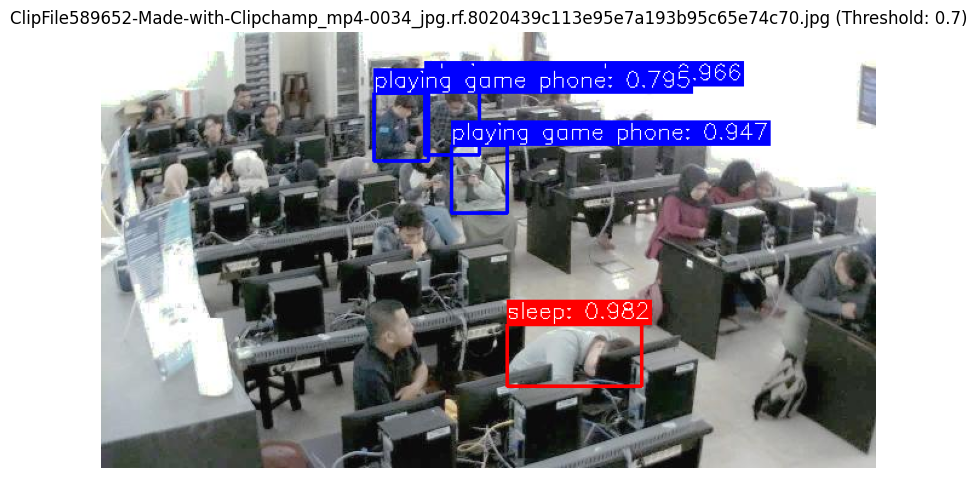

📋 Hasil Deteksi untuk ClipFile589652-Made-with-Clipchamp_mp4-0034_jpg.rf.8020439c113e95e7a193b95c65e74c70.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.982
1,2,playing game phone,0.966
2,3,playing game phone,0.947
3,4,playing game phone,0.795


--------------------------------------------------------------------------------


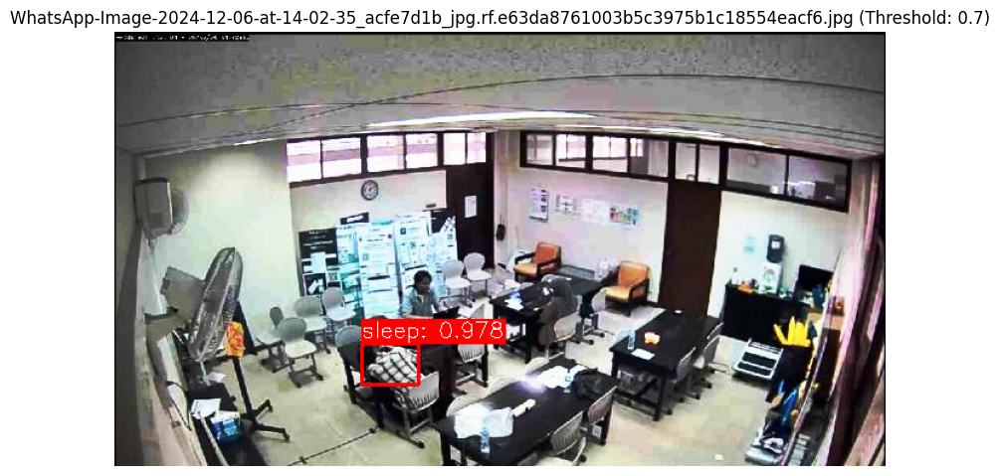

📋 Hasil Deteksi untuk WhatsApp-Image-2024-12-06-at-14-02-35_acfe7d1b_jpg.rf.e63da8761003b5c3975b1c18554eacf6.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.978


--------------------------------------------------------------------------------


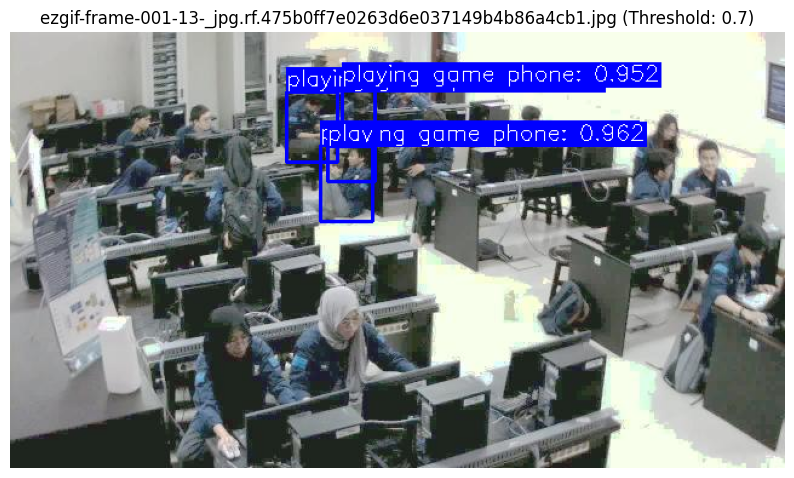

📋 Hasil Deteksi untuk ezgif-frame-001-13-_jpg.rf.475b0ff7e0263d6e037149b4b86a4cb1.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.991
1,2,playing game phone,0.990
2,3,playing game phone,0.962
3,4,playing game phone,0.952


--------------------------------------------------------------------------------


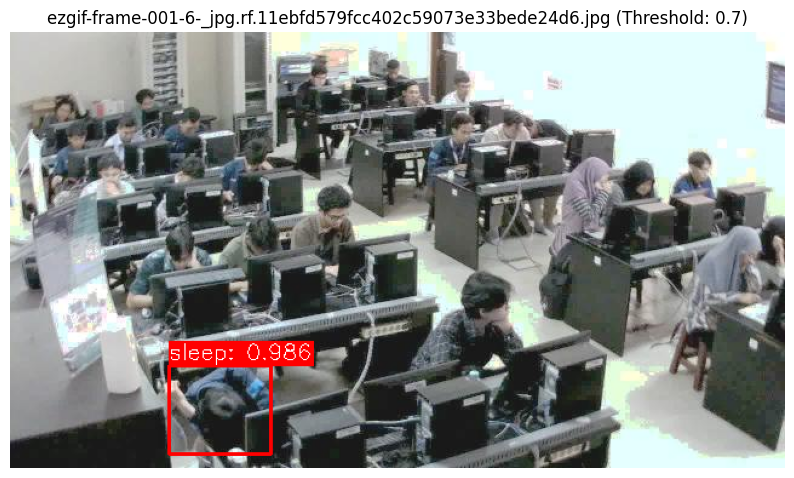

📋 Hasil Deteksi untuk ezgif-frame-001-6-_jpg.rf.11ebfd579fcc402c59073e33bede24d6.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.986


--------------------------------------------------------------------------------


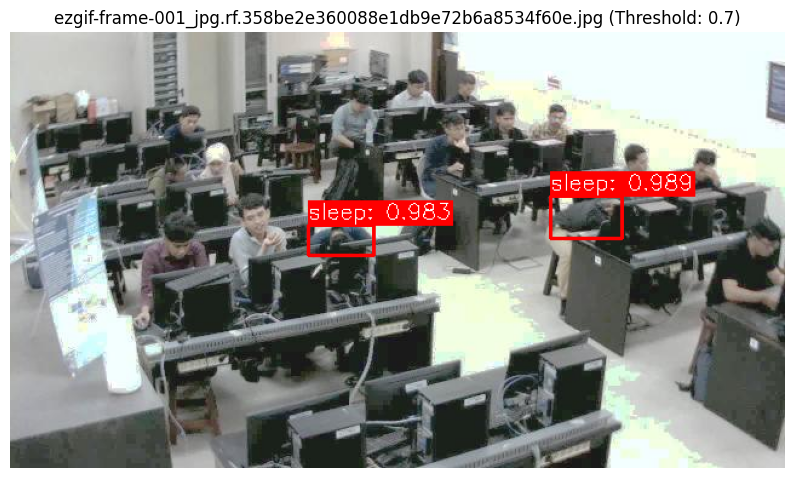

📋 Hasil Deteksi untuk ezgif-frame-001_jpg.rf.358be2e360088e1db9e72b6a8534f60e.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.989
1,2,sleep,0.983


--------------------------------------------------------------------------------


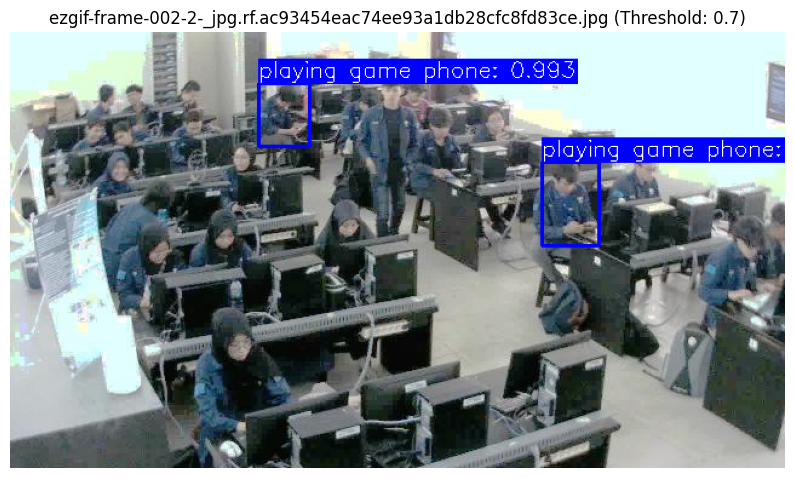

📋 Hasil Deteksi untuk ezgif-frame-002-2-_jpg.rf.ac93454eac74ee93a1db28cfc8fd83ce.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.993
1,2,playing game phone,0.942


--------------------------------------------------------------------------------


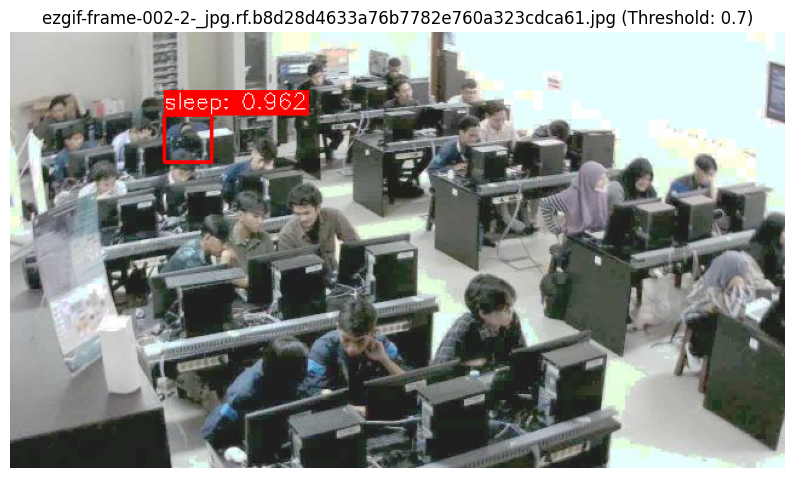

📋 Hasil Deteksi untuk ezgif-frame-002-2-_jpg.rf.b8d28d4633a76b7782e760a323cdca61.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.962


--------------------------------------------------------------------------------


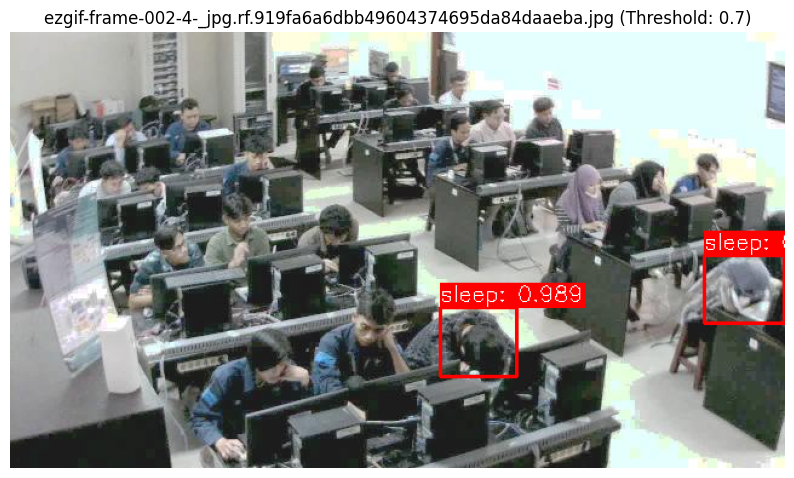

📋 Hasil Deteksi untuk ezgif-frame-002-4-_jpg.rf.919fa6a6dbb49604374695da84daaeba.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.989
1,2,sleep,0.986


--------------------------------------------------------------------------------


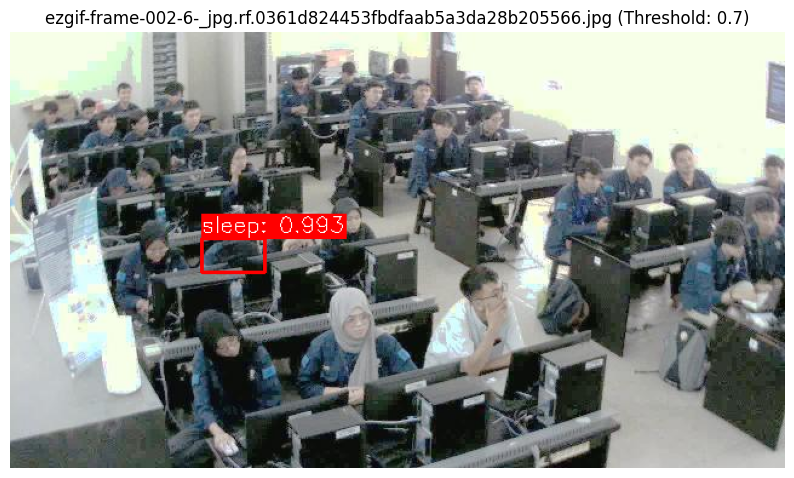

📋 Hasil Deteksi untuk ezgif-frame-002-6-_jpg.rf.0361d824453fbdfaab5a3da28b205566.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.993


--------------------------------------------------------------------------------


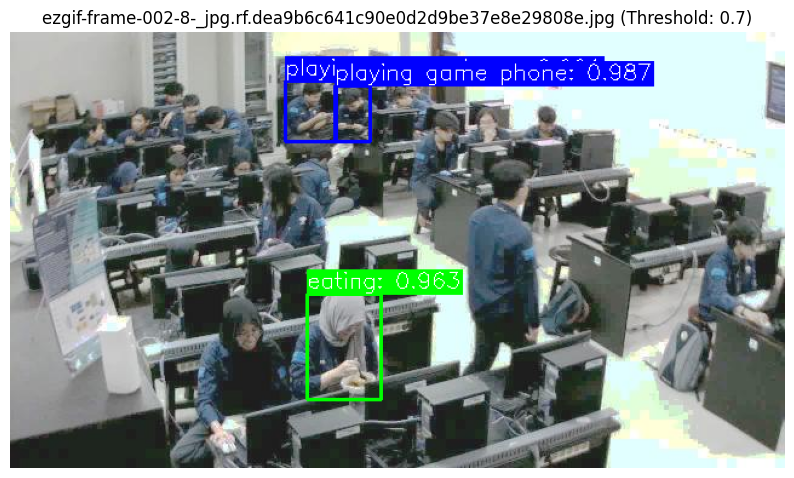

📋 Hasil Deteksi untuk ezgif-frame-002-8-_jpg.rf.dea9b6c641c90e0d2d9be37e8e29808e.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.991
1,2,playing game phone,0.987
2,3,eating,0.963


--------------------------------------------------------------------------------


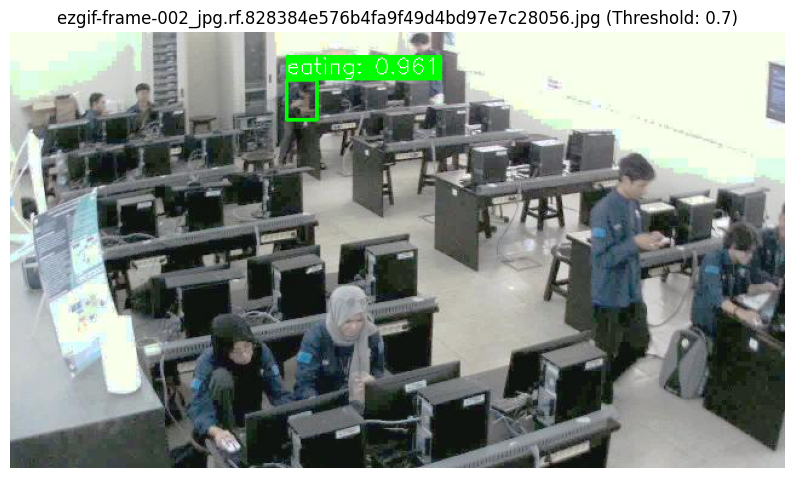

📋 Hasil Deteksi untuk ezgif-frame-002_jpg.rf.828384e576b4fa9f49d4bd97e7c28056.jpg:


,No,Pelanggaran,Confidence
0,1,eating,0.961


--------------------------------------------------------------------------------


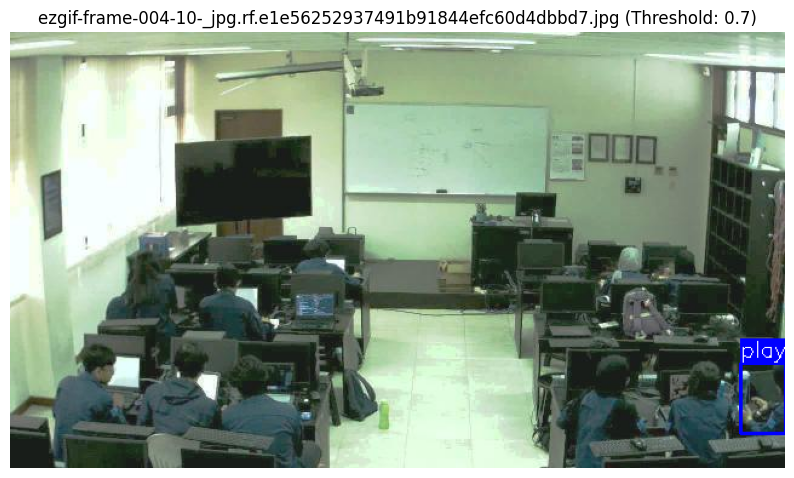

📋 Hasil Deteksi untuk ezgif-frame-004-10-_jpg.rf.e1e56252937491b91844efc60d4dbbd7.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.990


--------------------------------------------------------------------------------


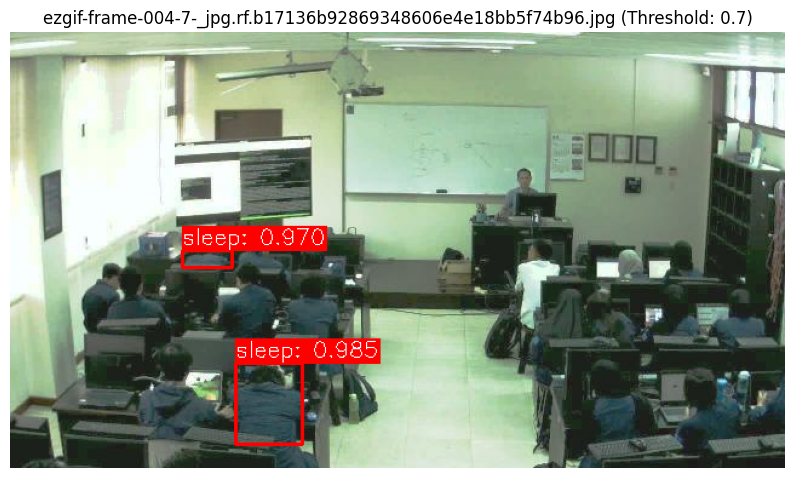

📋 Hasil Deteksi untuk ezgif-frame-004-7-_jpg.rf.b17136b92869348606e4e18bb5f74b96.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.985
1,2,sleep,0.970


--------------------------------------------------------------------------------


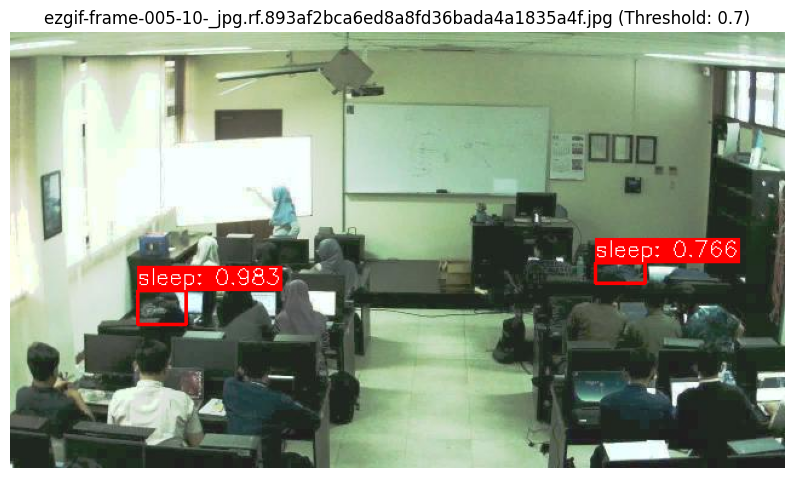

📋 Hasil Deteksi untuk ezgif-frame-005-10-_jpg.rf.893af2bca6ed8a8fd36bada4a1835a4f.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.983
1,2,sleep,0.766


--------------------------------------------------------------------------------


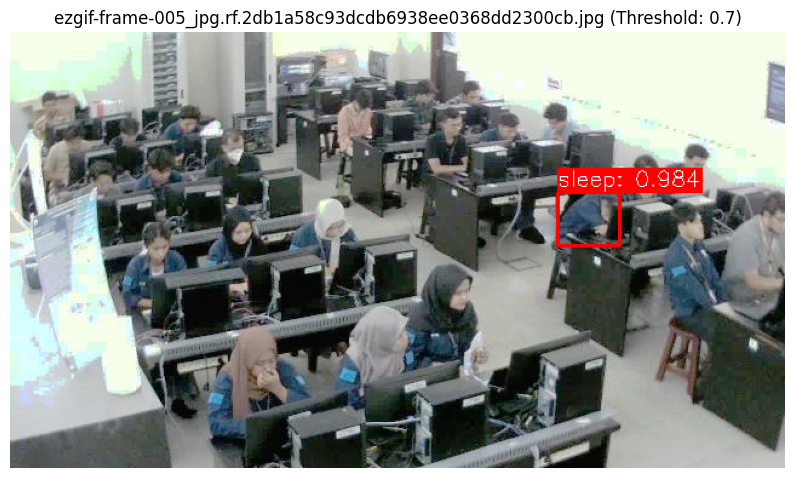

📋 Hasil Deteksi untuk ezgif-frame-005_jpg.rf.2db1a58c93dcdb6938ee0368dd2300cb.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.984


--------------------------------------------------------------------------------


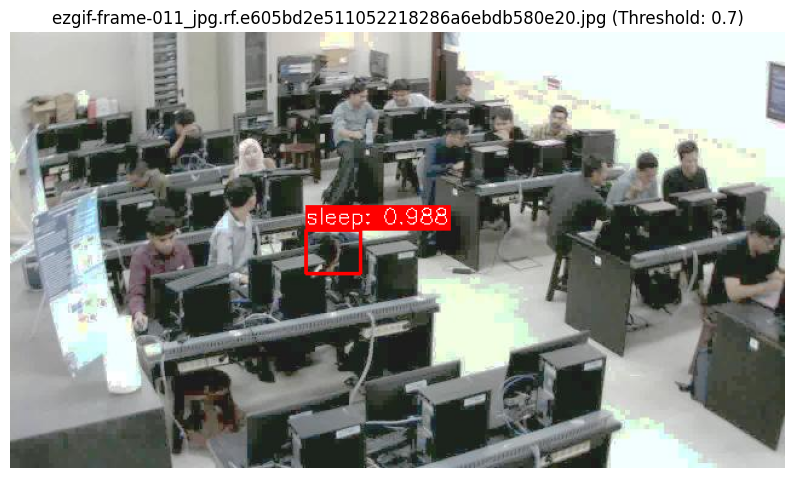

📋 Hasil Deteksi untuk ezgif-frame-011_jpg.rf.e605bd2e511052218286a6ebdb580e20.jpg:


,No,Pelanggaran,Confidence
0,1,sleep,0.988


--------------------------------------------------------------------------------


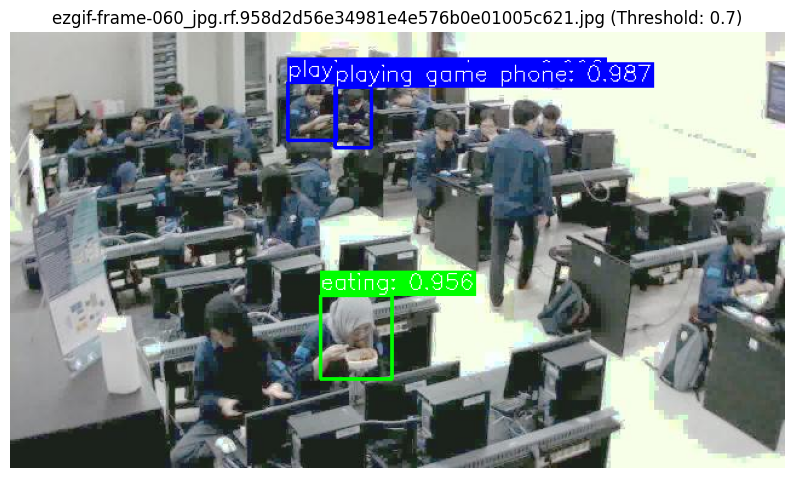

📋 Hasil Deteksi untuk ezgif-frame-060_jpg.rf.958d2d56e34981e4e576b0e01005c621.jpg:


,No,Pelanggaran,Confidence
0,1,playing game phone,0.992
1,2,playing game phone,0.987
2,3,eating,0.956


--------------------------------------------------------------------------------


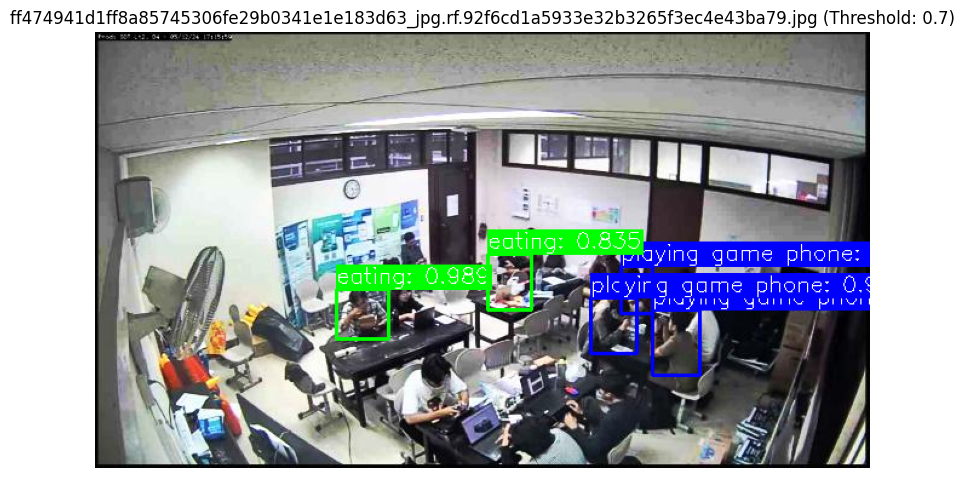

📋 Hasil Deteksi untuk ff474941d1ff8a85745306fe29b0341e1e183d63_jpg.rf.92f6cd1a5933e32b3265f3ec4e43ba79.jpg:


,No,Pelanggaran,Confidence
0,1,eating,0.989
1,2,playing game phone,0.983
2,3,playing game phone,0.977
3,4,playing game phone,0.897
4,5,eating,0.835


--------------------------------------------------------------------------------


In [13]:
# ==========================================
# CELL 13: VISUALISASI DETEKSI + TABEL DATA
# ==========================================

def visualize_test_with_table(model, dataset, device, threshold=0.7):
    model.eval()

    total_imgs = len(dataset)
    print(f"📂 Menampilkan {total_imgs} gambar dari Data Test (Urut)...")

    # Reverse map untuk label (ID -> Nama)
    # Pastikan ambil dari dataset yang benar
    if hasattr(dataset, 'class_map'):
        c_map = dataset.class_map
    else:
        c_map = dataset.dataset.class_map # Jika Subset

    rev_class_map = {v: k for k, v in c_map.items()}
    colors = [(0,0,0), (255,0,0), (0,0,255), (0,255,0)] # Warna Warni

    # Loop semua gambar secara berurutan
    for idx in range(total_imgs):
        img, target = dataset[idx]

        # Prediksi
        with torch.no_grad():
            prediction = model([img.to(device)])[0]

        # Konversi Image
        img_np = img.mul(255).permute(1, 2, 0).byte().numpy()
        img_np = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)

        boxes = prediction['boxes'].cpu().numpy()
        scores = prediction['scores'].cpu().numpy()
        labels = prediction['labels'].cpu().numpy()

        # List untuk menyimpan data tabel
        detections_data = []

        # Gambar Kotak
        for i in range(len(boxes)):
            if scores[i] > threshold:
                box = boxes[i].astype(int)
                label_id = labels[i]
                score = scores[i]

                label_name = rev_class_map.get(label_id, "Unknown")
                color = colors[label_id % len(colors)]

                # Simpan data untuk tabel
                detections_data.append({
                    "No": i+1,
                    "Pelanggaran": label_name,
                    "Confidence": f"{score:.3f}"
                })

                # Visualisasi
                cv2.rectangle(img_np, (box[0], box[1]), (box[2], box[3]), color, 2)
                text = f"{label_name}: {score:.3f}"
                (w, h), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 1)
                cv2.rectangle(img_np, (box[0], box[1] - 20), (box[0] + w, box[1]), color, -1)
                cv2.putText(img_np, text, (box[0], box[1] - 5),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 1)

        # --- TAMPILKAN HASIL ---

        # 1. Gambar
        plt.figure(figsize=(10, 6))
        plt.imshow(cv2.cvtColor(img_np, cv2.COLOR_BGR2RGB))
        plt.axis('off')

        # Judul (Nama File jika ada)
        fname = f"Image Index {idx}"
        if hasattr(dataset, 'imgs'):
            fname = dataset.imgs[idx]
        plt.title(f"{fname} (Threshold: {threshold})")
        plt.show()

        # 2. Tabel Deteksi
        if len(detections_data) > 0:
            df = pd.DataFrame(detections_data)
            # Tampilkan tabel cantik
            print(f"📋 Hasil Deteksi untuk {fname}:")
            display(df)
        else:
            print(f"⚪ Tidak ada pelanggaran terdeteksi pada {fname} (Score < {threshold})")

        print("-" * 80) # Separator antar gambar

# Jalankan Visualisasi
# Threshold bisa diatur, misal 0.5 sesuai standar skripsi Anda
visualize_test_with_table(model, dataset_test, DEVICE, threshold=0.7)